Installation and Imports

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

Load and clean the dataset

In [2]:
excel_path = "C:/Users/Benyamin/Documents/KAN/FinalDataNN.xlsx"
df = pd.read_excel(excel_path)

df_cleaned = df.dropna(subset=["P", "Y", "Ptest", "Ytest"])

P_train = df_cleaned["P"].values.astype("float32")
Y_train = df_cleaned["Y"].values.astype("float32")
P_test = df_cleaned["Ptest"].values.astype("float32")
Y_test = df_cleaned["Ytest"].values.astype("float32")

print(f"Train set size: {len(P_train)} samples")
print(f"Test set size: {len(P_test)} samples")

Train set size: 1072 samples
Test set size: 1072 samples


Hyper-parameters

In [8]:
K_S        = 3   # k: Spline order
G_S        = 5   # g: Grid size
IMIN       = 0.0 # NOTE: ReLU-KAN's basis grid is fixed to [0, 1] by construction
IMAX       = 1.0 #       (see quiqi/relu_kan) -- kept here only as a reminder to
                  #       scale P/Y into this range before training.
Batch_Size  = 32
Context_Len = 120
Pred_Len    = 20
H_Dims      = 32
N_Epochs    = 1500
Learning_Rate = 3e-4
Seq_Step = 5
Num_Layers  = 2
Bidirectional = False
SLOPE_INIT = 0.01  # initial value of the learnable PReLU slope (one shared scalar per layer, clamped to [0, 1], no weight decay). A slope of 0 is exactly ReLU-KAN.

Displaying Time Series

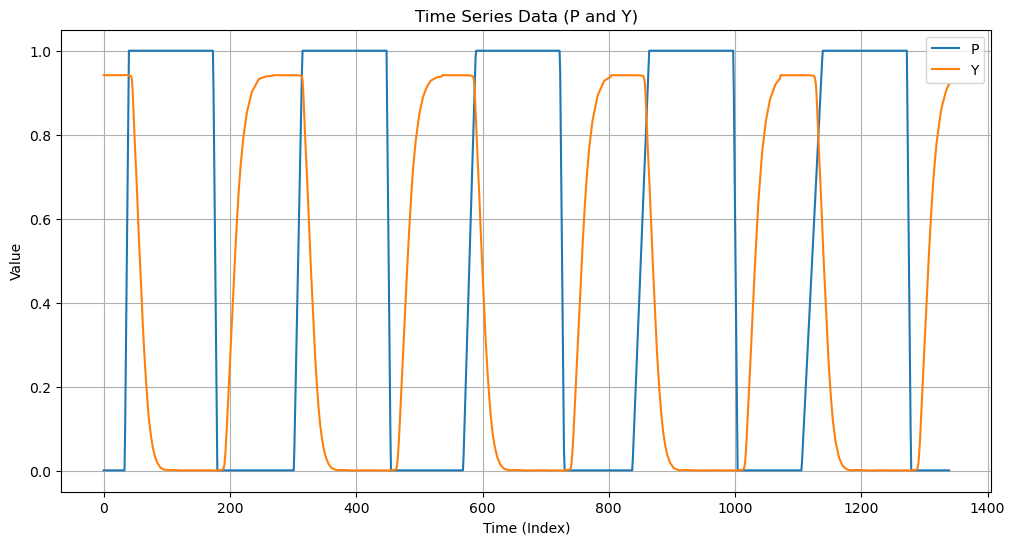

In [4]:
time_series_data_P = df["P"]
time_series_data_Y = df["Y"]

plt.figure(figsize=(12, 6))
plt.plot(time_series_data_P, label="P")
plt.plot(time_series_data_Y, label="Y")
plt.title("Time Series Data (P and Y)")
plt.xlabel("Time (Index)")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()

Sliding-window dataset (P → Y)

In [9]:
class PairedTimeSeriesDataset(Dataset):
    def __init__(self, x_series, y_series, context_len=Context_Len, pred_len=Pred_Len):
        self.x = torch.tensor(x_series, dtype=torch.float32)
        self.y = torch.tensor(y_series, dtype=torch.float32)
        self.context_len = context_len
        self.pred_len = pred_len
        self.total_len = context_len + pred_len
        self.n_samples = max(len(self.x) - self.total_len + 1, 0)

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        x_win = self.x[idx: idx + self.context_len]
        y_win = self.y[idx + self.context_len: idx + self.total_len]
        return x_win, y_win

train_dataset = PairedTimeSeriesDataset(P_train, Y_train)
test_dataset = PairedTimeSeriesDataset(P_test, Y_test)

train_loader = DataLoader(train_dataset, batch_size=Batch_Size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=Batch_Size, shuffle=False)

print(f"Train windows: {len(train_dataset)}")
print(f"Test windows: {len(test_dataset)}")

Train windows: 933
Test windows: 933


PReLU-KAN layer

In [10]:
class PReLUKANLayer(nn.Module):
    """
    PReLU-KAN basis layer -- derived from the ReLU-KAN layer of
    https://github.com/quiqi/relu_kan (torch_relu_kan.py).

    Only deviation from ReLU-KAN: both torch.relu calls in the basis
        R_i(x) = [ReLU(x - s_i) * ReLU(e_i - x) * r]^2
    are replaced by a PReLU with a LEARNABLE negative slope a:
        PReLU(z) = z if z > 0 else a * z
        R_i(x)   = [PReLU(x - s_i) * PReLU(e_i - x) * r]^2

    Safeguards for the learnable slope:
      * ONE shared scalar slope per layer (used by both factors, all inputs/bumps).
      * Clamped to [slope_min, slope_max] = [0, 1]: in the forward pass, and by a
        projection after every optimizer step (see project_slopes).
      * Excluded from weight decay (see the optimizer cell).
    a = 0 gives the original ReLU-KAN.
    """
    def __init__(self, input_size: int, g: int, k: int, output_size: int,
                 train_ab: bool = True, slope_init: float = 0.01,
                 slope_min: float = 0.0, slope_max: float = 1.0):
        super().__init__()
        self.g, self.k, self.r = g, k, 4 * g * g / ((k + 1) * (k + 1))
        self.input_size, self.output_size = input_size, output_size
        self.slope_min, self.slope_max = slope_min, slope_max

        phase_low = np.arange(-k, g) / g
        phase_height = phase_low + (k + 1) / g

        self.phase_low = nn.Parameter(
            torch.Tensor(np.array([phase_low for _ in range(input_size)])),
            requires_grad=train_ab
        )
        self.phase_height = nn.Parameter(
            torch.Tensor(np.array([phase_height for _ in range(input_size)])),
            requires_grad=train_ab
        )
        self.slope = nn.Parameter(torch.tensor(float(slope_init)))
        self.equal_size_conv = nn.Conv2d(1, output_size, (g + k, input_size))

    def _prelu(self, z):
        a = self.slope.clamp(self.slope_min, self.slope_max)
        return torch.where(z > 0, z, a * z)

    def forward(self, x):
        # x: (batch, input_size)
        x_expanded = x.unsqueeze(2).expand(-1, -1, self.phase_low.size(1))

        x1 = self._prelu(x_expanded - self.phase_low)
        x2 = self._prelu(self.phase_height - x_expanded)
        x = x1 * x2 * self.r
        x = x * x

        x = x.reshape((len(x), 1, self.g + self.k, self.input_size))
        x = self.equal_size_conv(x)
        x = x.reshape((len(x), self.output_size))
        return x

class PReLUKAN(nn.Module):
    """Stack of PReLUKANLayer (same wrapper as upstream's ReLUKAN)."""
    def __init__(self, width, grid, k, slope_init=0.01):
        super().__init__()
        self.rk_layers = nn.ModuleList([
            PReLUKANLayer(width[i], grid, k, width[i + 1], slope_init=slope_init)
            for i in range(len(width) - 1)
        ])

    def forward(self, x):
        for rk_layer in self.rk_layers:
            x = rk_layer(x)
        return x

def project_slopes(model):
    """Projection step: keep every learnable slope inside [slope_min, slope_max].
    Call right after optimizer.step()."""
    with torch.no_grad():
        for m in model.modules():
            if hasattr(m, "slope") and hasattr(m, "slope_min"):
                m.slope.clamp_(m.slope_min, m.slope_max)

PReLU-KAN recurrent blocks

In [11]:
class PReLUKANRNNCell(nn.Module):
    """
    A genuinely recurrent KAN cell: the hidden-state update
        h_t = PReLUKAN([x_t ; h_{t-1}])
    is computed by a PReLU-KAN layer instead of the Linear + activation used by
    a vanilla RNN cell.
    """
    def __init__(self, input_size, hidden_size, grid, k, slope_init=0.01):
        super().__init__()
        self.hidden_size = hidden_size
        self.rk = PReLUKAN(
            width=[input_size + hidden_size, hidden_size],
            grid=grid,
            k=k,
            slope_init=slope_init
        )

    def forward(self, x_t, h_prev):
        combined = torch.cat([x_t, h_prev], dim=1)
        h_t = self.rk(combined)
        return h_t

class PReLUKANRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, grid, k, slope_init=0.01):
        super().__init__()
        self.hidden_size = hidden_size
        self.cell = PReLUKANRNNCell(input_size, hidden_size, grid, k, slope_init)
        self.readout = nn.Linear(hidden_size, output_size)

    def forward(self, x, h0=None):
        batch_size, seq_len, _ = x.shape
        if h0 is None:
            h_t = torch.zeros(batch_size, self.hidden_size, device=x.device, dtype=x.dtype)
        else:
            h_t = h0

        outputs = []
        for t in range(seq_len):
            h_t = self.cell(x[:, t, :], h_t)   # <-- recurrence: h_t depends on h_{t-1}
            outputs.append(self.readout(h_t).unsqueeze(1))

        outputs = torch.cat(outputs, dim=1)
        return outputs, h_t

Main model: Recurrent PReLU-KAN

In [12]:
class RecurrentPReLUKAN(nn.Module):
    def __init__(self, context_len: int, pred_len: int, g: int, k: int, kan_out_dim: int, rnn_hidden: int,
                 seq_step: int = 10, slope_init: float = 0.01):
        super().__init__()
        assert context_len % seq_step == 0, "context_len must be a multiple of seq_step"

        self.context_len = context_len
        self.pred_len = pred_len
        self.seq_step = seq_step
        self.num_steps = context_len // seq_step

        # Shared PReLU-KAN "embedding" applied to every chunk of the window
        self.kan = PReLUKANLayer(
            input_size=seq_step,
            g=g,
            k=k,
            output_size=kan_out_dim,
            train_ab=True,
            slope_init=slope_init
        )

        # Genuine recurrence: a PReLU-KAN-based RNN cell scanned over num_steps
        self.rnn = PReLUKANRNN(
            input_size=kan_out_dim,
            hidden_size=rnn_hidden,
            output_size=rnn_hidden,
            grid=g,
            k=k,
            slope_init=slope_init
        )

        self.fc_out = nn.Linear(rnn_hidden, pred_len)

    def forward(self, x):
        if x.dim() == 2:
            b, L = x.shape
        elif x.dim() == 3 and x.size(-1) == 1:
            x = x.squeeze(-1)
            b, L = x.shape
        else:
            raise ValueError(f"Unsupported input shape {x.shape}")

        assert L == self.context_len, f"Expected context_len={self.context_len}, got {L}"

        x_steps = x.view(b, self.num_steps, self.seq_step)
        kan_out = self.kan(x_steps.reshape(b * self.num_steps, self.seq_step))
        kan_seq = kan_out.view(b, self.num_steps, -1)

        _, h_last = self.rnn(kan_seq)   # scans over num_steps timesteps recurrently
        return self.fc_out(h_last)

Training utilities

In [13]:
def mae(y_true, y_pred):
    return torch.mean(torch.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return torch.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return torch.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_total = torch.sum((y_true - torch.mean(y_true)) ** 2)
    ss_residual = torch.sum((y_true - y_pred) ** 2)
    return 1 - (ss_residual / ss_total) if ss_total > 0 else torch.tensor(0.0, device=y_true.device)

def signal_to_noise_ratio(y_true, y_pred):
    # Assuming y_pred is the 'signal' and (y_true - y_pred) is the 'noise'
    signal_power = torch.mean(y_pred ** 2)
    noise_power = torch.mean((y_true - y_pred) ** 2)
    if noise_power == 0:
        return torch.tensor(float('inf'), device=y_true.device)
    return 10 * torch.log10(signal_power / noise_power)

def smape(y_true, y_pred):
    numerator = torch.abs(y_pred - y_true)
    denominator = (torch.abs(y_true) + torch.abs(y_pred)) / 2
    smape_values = torch.where(denominator == 0, torch.tensor(0.0, device=y_true.device), numerator / denominator)
    return torch.mean(smape_values) * 100

def nrmse_range(y_true, y_pred):
    rmse_val = rmse(y_true, y_pred)
    y_range = torch.max(y_true) - torch.min(y_true)
    return (rmse_val / y_range) * 100 if y_range > 0 else torch.tensor(0.0, device=y_true.device)

def nrmse_std(y_true, y_pred):
    rmse_val = rmse(y_true, y_pred)
    y_std = torch.std(y_true)
    return (rmse_val / y_std) * 100 if y_std > 0 else torch.tensor(0.0, device=y_true.device)

def pointwise_relative_error(y_true, y_pred):
    err = torch.where(y_true == 0, torch.tensor(0.0, device=y_true.device), torch.abs(y_true - y_pred) / torch.abs(y_true))
    return torch.mean(err) * 100

def compute_stats(loader, model, device):
    model.eval()
    tot_mae, tot_mse, tot_samples = 0.0, 0.0, 0
    y_true_all = []
    y_pred_all = []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            y_pred = model(x)
            tot_mae += mae(y_pred, y).item() * y.numel()
            tot_mse += mse(y_pred, y).item() * y.numel()
            tot_samples += y.numel()
            y_true_all.append(y.cpu())
            y_pred_all.append(y_pred.cpu())

    y_true_all = torch.cat(y_true_all)
    y_pred_all = torch.cat(y_pred_all)

    final_mae = tot_mae / tot_samples
    final_mse = tot_mse / tot_samples
    final_rmse = torch.sqrt(torch.tensor(final_mse, device=device))

    return final_mae, final_mse, final_rmse, y_true_all, y_pred_all

Device, model, optimizer, criterion

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = RecurrentPReLUKAN(
    context_len=Context_Len,
    pred_len=Pred_Len,
    g=G_S,
    k=K_S,
    kan_out_dim=H_Dims,
    rnn_hidden=H_Dims,
    seq_step=Seq_Step,
    slope_init=SLOPE_INIT
).to(device)

# The learnable PReLU slopes get NO weight decay (AdamW would otherwise pull them to 0, i.e. back to ReLU).
slope_params = [p for n, p in model.named_parameters() if n.endswith("slope")]
other_params = [p for n, p in model.named_parameters() if not n.endswith("slope")]
optimizer = torch.optim.AdamW(
    [
        {"params": other_params},                          # default AdamW weight decay, as in the original notebook
        {"params": slope_params, "weight_decay": 0.0},     # no weight decay on the slopes
    ],
    lr=Learning_Rate
)
criterion = nn.L1Loss()

Using device: cpu


Training loop with timing

In [15]:
train_history = []
test_history = []
train_times = []
infer_times = []
per_iteration_train_times = []
total_train_time = 0.0

for epoch in range(1, N_Epochs + 1):
    epoch_start = time.perf_counter()
    model.train()
    running_loss = 0.0

    for x, y in train_loader:
        start_time = time.perf_counter()
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        y_pred = model(x)
        loss = criterion(y_pred, y)
        loss.backward()
        optimizer.step()
        project_slopes(model)
        running_loss += loss.item() * x.size(0)
        per_iteration_train_times.append(time.perf_counter() - start_time)

    epoch_time = time.perf_counter() - epoch_start
    train_times.append(epoch_time)
    total_train_time += epoch_time

    # compute_stats now returns RMSE and y_true_all, y_pred_all
    train_mae, train_mse, train_rmse_val, _, _ = compute_stats(train_loader, model, device)
    test_mae, test_mse, test_rmse_val, _, _ = compute_stats(test_loader, model, device)

    train_history.append((train_mae, train_mse, train_rmse_val))
    test_history.append((test_mae, test_mse, test_rmse_val))

    infer_start = time.perf_counter()
    # Call compute_stats again, but discard the y_true_all and y_pred_all as we only need timing
    _, _, _, _, _ = compute_stats(test_loader, model, device)
    infer_time = time.perf_counter() - infer_start
    infer_times.append(infer_time)

    print(
        f"Epoch {epoch:04d} | "
        f"Loss {running_loss/len(train_loader.dataset):.6f} | "
        f"Train MAE {train_mae:.6f} | Train MSE {train_mse:.6f} | Train RMSE {train_rmse_val:.6f} | "
        f"Test MAE {test_mae:.6f} | Test MSE {test_mse:.6f} | Test RMSE {test_rmse_val:.6f} | "
        f"Train time {epoch_time:.2f}s | Inference time {infer_time:.2f}s"
    )

Epoch 0001 | Loss 0.340021 | Train MAE 0.238013 | Train MSE 0.138895 | Train RMSE 0.372686 | Test MAE 0.233445 | Test MSE 0.135255 | Test RMSE 0.367770 | Train time 1.40s | Inference time 0.35s
Epoch 0002 | Loss 0.156138 | Train MAE 0.079908 | Train MSE 0.021597 | Train RMSE 0.146958 | Test MAE 0.079833 | Test MSE 0.021727 | Test RMSE 0.147401 | Train time 1.33s | Inference time 0.41s
Epoch 0003 | Loss 0.059847 | Train MAE 0.040413 | Train MSE 0.005983 | Train RMSE 0.077347 | Test MAE 0.041213 | Test MSE 0.006224 | Test RMSE 0.078893 | Train time 1.35s | Inference time 0.41s
Epoch 0004 | Loss 0.032462 | Train MAE 0.028432 | Train MSE 0.003230 | Train RMSE 0.056831 | Test MAE 0.028875 | Test MSE 0.003314 | Test RMSE 0.057563 | Train time 1.31s | Inference time 0.40s
Epoch 0005 | Loss 0.025098 | Train MAE 0.022260 | Train MSE 0.002006 | Train RMSE 0.044783 | Test MAE 0.022028 | Test MSE 0.002002 | Test RMSE 0.044748 | Train time 1.26s | Inference time 0.38s
Epoch 0006 | Loss 0.020089 | T

Final evaluation & speed-up

In [16]:
final_train_mae, final_train_mse, final_train_rmse_tensor, y_true_train_final, y_pred_train_final = compute_stats(train_loader, model, device)
final_test_mae, final_test_mse, final_test_rmse_tensor, y_true_test_final, y_pred_test_final = compute_stats(test_loader, model, device)

final_train_rmse = final_train_rmse_tensor.item()
final_test_rmse = final_test_rmse_tensor.item()

def physics_simulation(x_batch):
    time.sleep(0.0001 * x_batch.shape[0])

physics_start = time.perf_counter()
for x, _ in test_loader:
    physics_simulation(x.to(device))
physics_time = time.perf_counter() - physics_start

avg_infer_time = np.mean(infer_times)
speedup = physics_time / (avg_infer_time * len(test_loader))

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

avg_epoch_train_time = np.mean(train_times)

# Calculate all other metrics
train_r2 = r2_score(y_true_train_final, y_pred_train_final).item()
test_r2 = r2_score(y_true_test_final, y_pred_test_final).item()

train_snr = signal_to_noise_ratio(y_true_train_final, y_pred_train_final).item()
test_snr = signal_to_noise_ratio(y_true_test_final, y_pred_test_final).item()

train_smape = smape(y_true_train_final, y_pred_train_final).item()
test_smape = smape(y_true_test_final, y_pred_test_final).item()

train_nrmse_range = nrmse_range(y_true_train_final, y_pred_train_final).item()
test_nrmse_range = nrmse_range(y_true_test_final, y_pred_test_final).item()

train_nrmse_std = nrmse_std(y_true_train_final, y_pred_train_final).item()
test_nrmse_std = nrmse_std(y_true_test_final, y_pred_test_final).item()

train_pt_rel_err = pointwise_relative_error(y_true_train_final, y_pred_train_final).item()
test_pt_rel_err = pointwise_relative_error(y_true_test_final, y_pred_test_final).item()

results_df = pd.DataFrame({
    "Metric": [
        "Train MAE", "Test MAE",
        "Train MSE", "Test MSE",
        "Train RMSE", "Test RMSE",
        "Train R2", "Test R2",
        "Train SNR (dB)", "Test SNR (dB)",
        "Train SMAPE (%)", "Test SMAPE (%)",
        "Train NRMSE, range-normalized (%)", "Test NRMSE, range-normalized (%)",
        "Train NRMSE, std-normalized (%)", "Test NRMSE, std-normalized (%)",
        "[reference only, unstable] Train pointwise rel. error (%)",
        "[reference only, unstable] Test pointwise rel. error (%)",
        "[PLACEHOLDER, not physical] Speedup (sleep-proxy / GFKAN)",
        "Total Training Time (s)",
        "Test Time (s)",
        "Average Epoch Training Time (s)",
        "Per-Iteration Training Time (s)",
        "Total number of trainable parameters",
        "Epochs Run",
        "Structure"
    ],
    "Value": [
        final_train_mae, final_test_mae,
        final_train_mse, final_test_mse,
        final_train_rmse, final_test_rmse,
        train_r2, test_r2,
        train_snr, test_snr,
        train_smape, test_smape,
        train_nrmse_range, test_nrmse_range,
        train_nrmse_std, test_nrmse_std,
        train_pt_rel_err, test_pt_rel_err,
        speedup,
        total_train_time,
        avg_infer_time,
        avg_epoch_train_time,
        np.mean(per_iteration_train_times),
        count_parameters(model),
        N_Epochs,
        str(model)
    ]
})

print("\n--- Summary of Results (Markdown) ---")
print(results_df.to_markdown(index=False))


--- Summary of Results (Markdown) ---
| Metric                                                    | Value                                                                            |
|:----------------------------------------------------------|:---------------------------------------------------------------------------------|
| Train MAE                                                 | 0.0016043556128935                                                               |
| Test MAE                                                  | 0.0032724963770859893                                                            |
| Train MSE                                                 | 2.4139536617951945e-05                                                           |
| Test MSE                                                  | 6.112172329534293e-05                                                            |
| Train RMSE                                                | 0.004913200158625841         

Plot training history

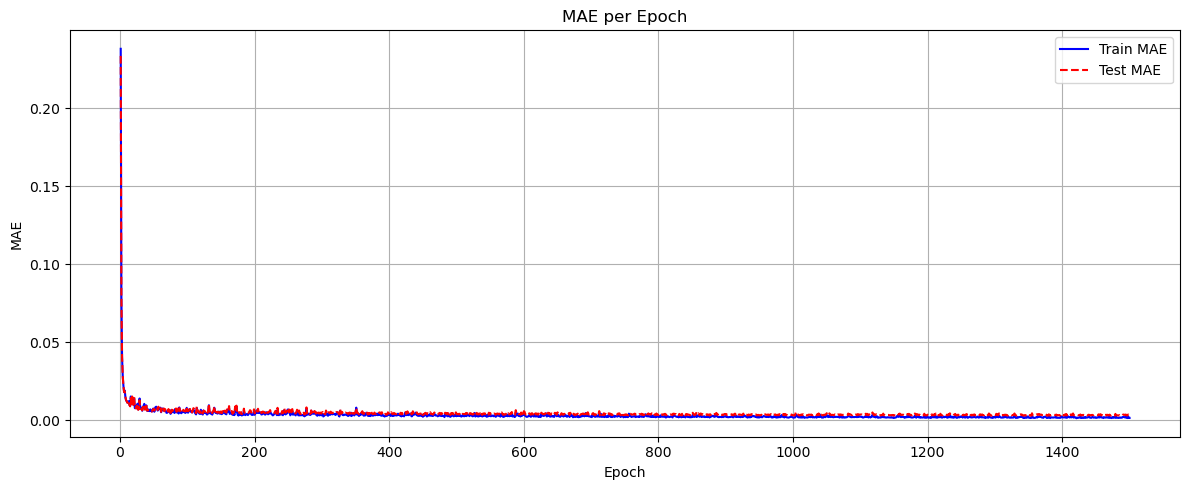

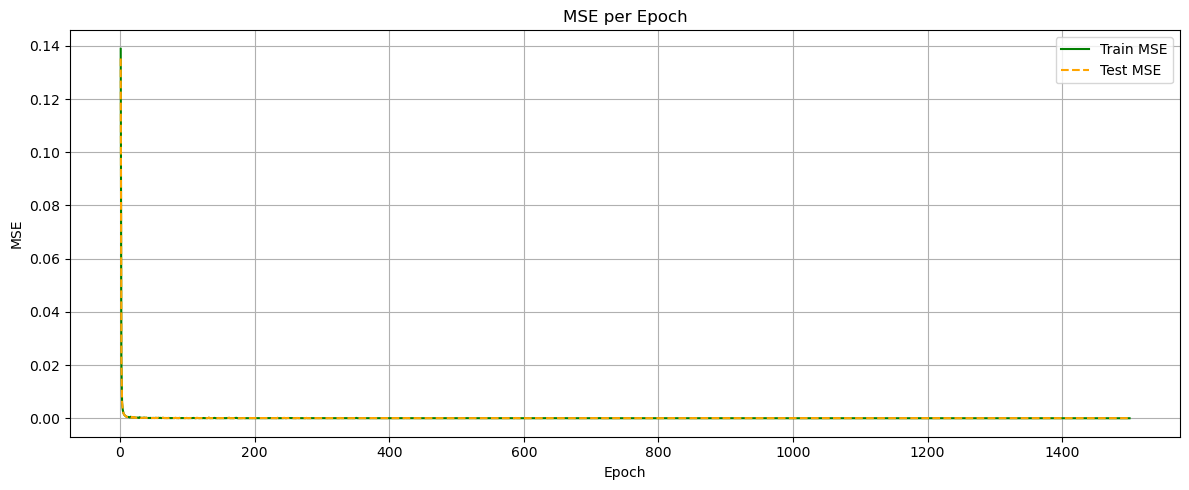

In [17]:
epochs = range(1, N_Epochs + 1)
train_mae_hist = [h[0] for h in train_history]
train_mse_hist = [h[1] for h in train_history]
test_mae_hist = [h[0] for h in test_history]
test_mse_hist = [h[1] for h in test_history]

plt.figure(figsize=(12, 5))
plt.plot(epochs, train_mae_hist, label="Train MAE", color="blue")
plt.plot(epochs, test_mae_hist, label="Test MAE", color="red", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("MAE per Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(epochs, train_mse_hist, label="Train MSE", color="green")
plt.plot(epochs, test_mse_hist, label="Test MSE", color="orange", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("MSE per Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Full test-set prediction vs ground truth

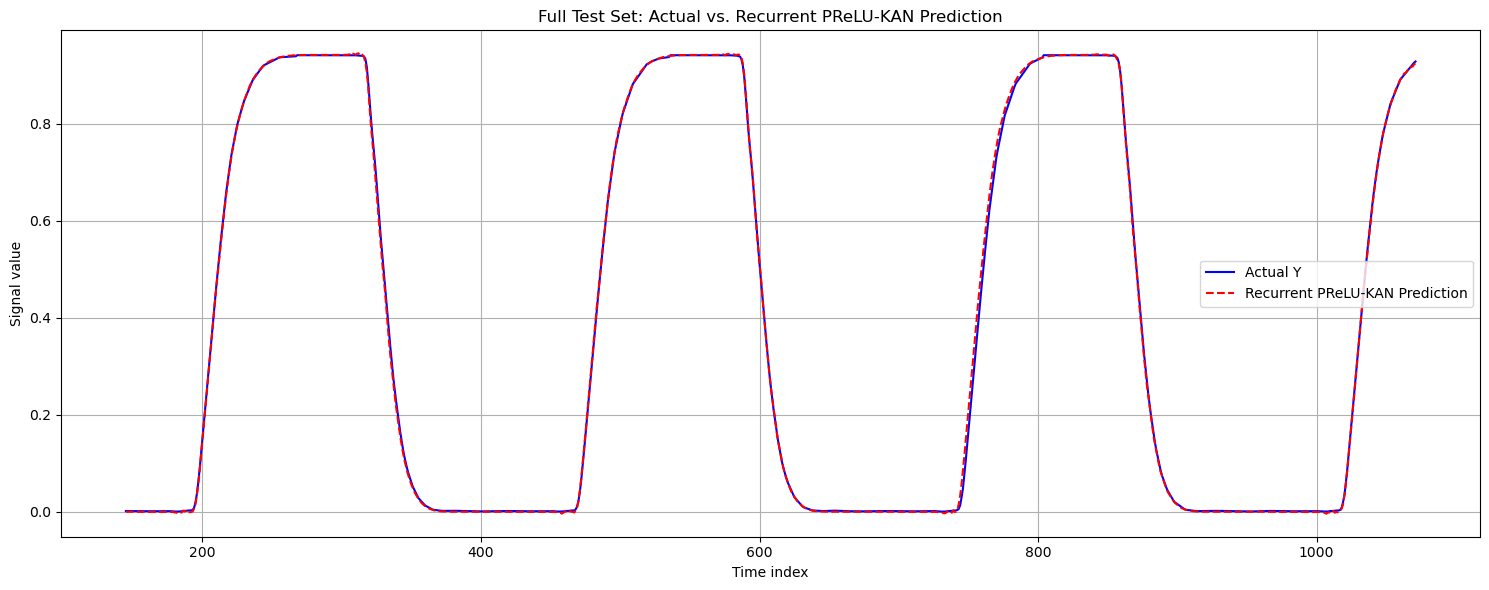

In [18]:
model.eval()
full_predicted_Y_test = np.full_like(Y_test, np.nan, dtype=np.float64)

with torch.no_grad():
    for idx in range(len(test_dataset)):
        x_win, _ = test_dataset[idx]
        x_win = x_win.unsqueeze(0).to(device)
        y_pred_win = model(x_win).cpu().squeeze(0).numpy()

        start_idx = idx + Context_Len
        end_idx = start_idx + Pred_Len
        if start_idx < len(Y_test):
            full_predicted_Y_test[start_idx:min(end_idx, len(Y_test))] = y_pred_win[:min(Pred_Len, len(Y_test) - start_idx)]

start_plot = 145
plt.figure(figsize=(15, 6))
plt.plot(np.arange(start_plot, len(Y_test)), Y_test[start_plot:], label="Actual Y", color="blue")
plt.plot(np.arange(start_plot, len(full_predicted_Y_test)), full_predicted_Y_test[start_plot:],
         label="Recurrent PReLU-KAN Prediction", color="red", linestyle="--")
plt.xlabel("Time index")
plt.ylabel("Signal value")
plt.title("Full Test Set: Actual vs. Recurrent PReLU-KAN Prediction")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Diagnostics: data range and activation range vs. the [0, 1] KAN grid

In [19]:
# Data range (the KAN grid lives on [0, 1])
for name, arr in [("P_train", P_train), ("Y_train", Y_train), ("P_test", P_test), ("Y_test", Y_test)]:
    print(f"{name}: min={arr.min():.4f}  max={arr.max():.4f}  outside [0,1]: {100*np.mean((arr < 0) | (arr > 1)):.1f}%")

# Range of the recurrent hidden state fed back into the KAN cell, per time step
hs = []
hook = model.rnn.cell.register_forward_hook(lambda m, i, o: hs.append(o.detach().cpu()))
model.eval()
with torch.no_grad():
    xb, _ = next(iter(test_loader))
    model(xb.to(device))
hook.remove()
h_all = torch.cat(hs)
print(f"hidden state h_t: min={h_all.min():.4f}  max={h_all.max():.4f}  outside [0,1]: {100*((h_all < 0) | (h_all > 1)).float().mean():.1f}%")

# Learned PReLU slopes (one scalar per layer, kept in [0, 1]); a = 0 would mean plain ReLU basis
for n, p in model.named_parameters():
    if n.endswith("slope"):
        print(f"{n}: {p.item():.4f}")


P_train: min=0.0009  max=1.0000  outside [0,1]: 0.0%
Y_train: min=0.0001  max=0.9423  outside [0,1]: 0.0%
P_test: min=0.0009  max=1.0000  outside [0,1]: 0.0%
Y_test: min=0.0001  max=0.9421  outside [0,1]: 0.0%
hidden state h_t: min=-1.3295  max=1.3379  outside [0,1]: 54.3%
kan.slope: 0.0000
rnn.cell.rk.rk_layers.0.slope: 0.0000
